# Lagos Weather API Analytics

## Project Overview

This project focuses on analyzing 30 days of historical weather data for Lagos, Nigeria, using the Open-Meteo API.

Python is used to collect, clean, analyze, and visualize weather data, including temperature, relative humidity, and precipitation.

The project also includes an interactive Power BI dashboard to present weather trends, patterns, and key insights.

## Project Objectives

The objectives of this project are to:

1. Retrieve 30 days of historical weather data for Lagos, Nigeria, using the Open-Meteo API.
2. Clean and prepare the data for analysis using Python and Pandas.
3. Analyze daily temperature, rainfall, and humidity patterns.
4. Investigate relationships between weather variables using correlation analysis.
5. Identify the hottest and rainiest days during the study period.
6. Develop an interactive Power BI dashboard to visualize weather trends and communicate key insights.

## Import Libraries

In [2]:
import requests
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime, timedelta

## Data Collection



In [3]:
end_date = datetime.now().date() - timedelta(days=1)
start_date = end_date - timedelta(days=29)

url = "https://archive-api.open-meteo.com/v1/archive"

params = {
    "latitude": 6.45,
    "longitude": 3.39,
    "start_date": str(start_date),
    "end_date": str(end_date),
    "hourly": "temperature_2m,relative_humidity_2m,precipitation",
    "timezone": "Africa/Lagos"
}

### Fetch Weather Data

Send an HTTP request to the Open-Meteo API and convert the response into JSON format.

In [4]:
response = requests.get(url, params=params)
response.raise_for_status()

data = response.json()

In [5]:
df = pd.DataFrame(data["hourly"])

df.head()

,time,temperature_2m,relative_humidity_2m,precipitation
0,2026-09-22T00:00,25.7,90,0.0
1,2026-09-22T01:00,25.7,86,0.1
2,2026-09-22T02:00,25.5,87,0.0
3,2026-09-22T03:00,25.4,88,0.0
4,2026-09-22T04:00,25.1,88,0.0


## Data Inspection



In [6]:
df.shape


(720, 4)

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   time                  720 non-null    str    
 1   temperature_2m        720 non-null    float64
 2   relative_humidity_2m  720 non-null    int64  
 3   precipitation         720 non-null    float64
dtypes: float64(2), int64(1), str(1)
memory usage: 33.9 KB


In [8]:
df.isnull().sum()/len(df)

time                    0.0
temperature_2m          0.0
relative_humidity_2m    0.0
precipitation           0.0
dtype: float64

In [9]:
df.duplicated().sum()

np.int64(0)

In [10]:
df["time"] = pd.to_datetime(df["time"])

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 720 entries, 0 to 719
Data columns (total 4 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  720 non-null    datetime64[us]
 1   temperature_2m        720 non-null    float64       
 2   relative_humidity_2m  720 non-null    int64         
 3   precipitation         720 non-null    float64       
dtypes: datetime64[us](1), float64(2), int64(1)
memory usage: 22.6 KB


In [11]:
df.describe()

,time,temperature_2m,relative_humidity_2m,precipitation
count,720,720.000000,720.000000,720.000000
mean,2026-10-06 23:30:00,26.966944,83.455556,0.203056
min,2026-09-22 00:00:00,23.900000,64.000000,0.000000
25%,2026-09-29 11:45:00,26.000000,79.000000,0.000000
50%,2026-10-06 23:30:00,26.700000,84.000000,0.000000
75%,2026-10-14 11:15:00,27.900000,88.000000,0.100000
max,2026-10-21 23:00:00,31.200000,98.000000,7.600000
std,NaN,1.353178,6.353580,0.616095


## Exploratory Data Analysis (EDA) and Visualization



In [12]:
daily_temp = (
    df.groupby(df["time"].dt.date)["temperature_2m"]
    .mean()
    .reset_index()
)

daily_temp.head()

,time,temperature_2m
0,2026-09-22,26.087500
1,2026-09-23,25.454167
2,2026-09-24,26.241667
3,2026-09-25,26.466667
4,2026-09-26,26.554167


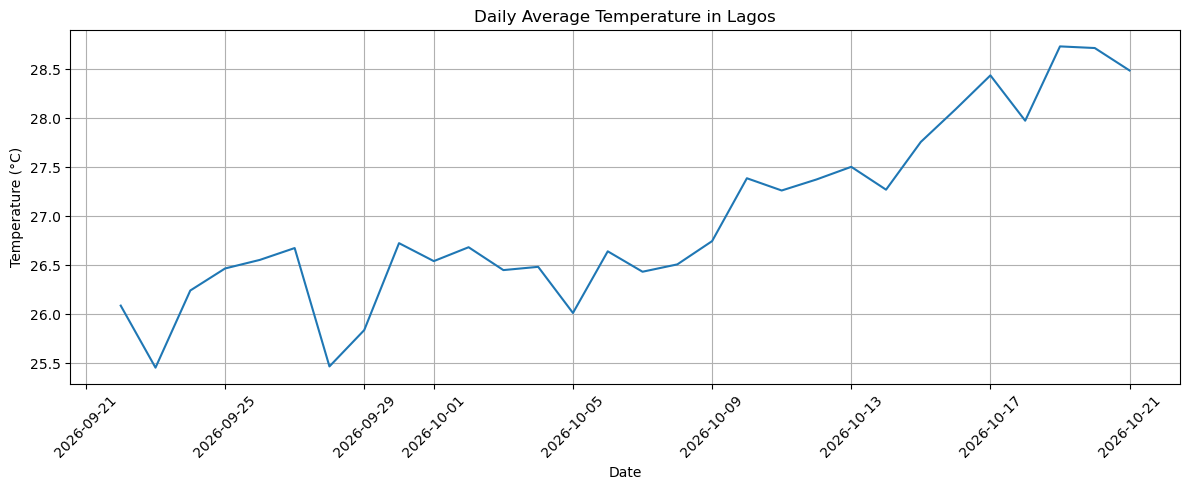

In [13]:


plt.figure(figsize=(12, 5))

plt.plot(daily_temp["time"], daily_temp["temperature_2m"])

plt.title("Daily Average Temperature in Lagos")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**Observation:** Daily average temperature fluctuated throughout the period but showed an overall upward trend, rising from approximately 26.2°C to 28.7°C.

In [14]:
daily_rainfall = (
    df.groupby(df["time"].dt.date)["precipitation"]
    .sum()
    .reset_index()
)

daily_rainfall.head()

,time,precipitation
0,2026-09-22,4.8
1,2026-09-23,13.3
2,2026-09-24,1.8
3,2026-09-25,1.0
4,2026-09-26,11.3


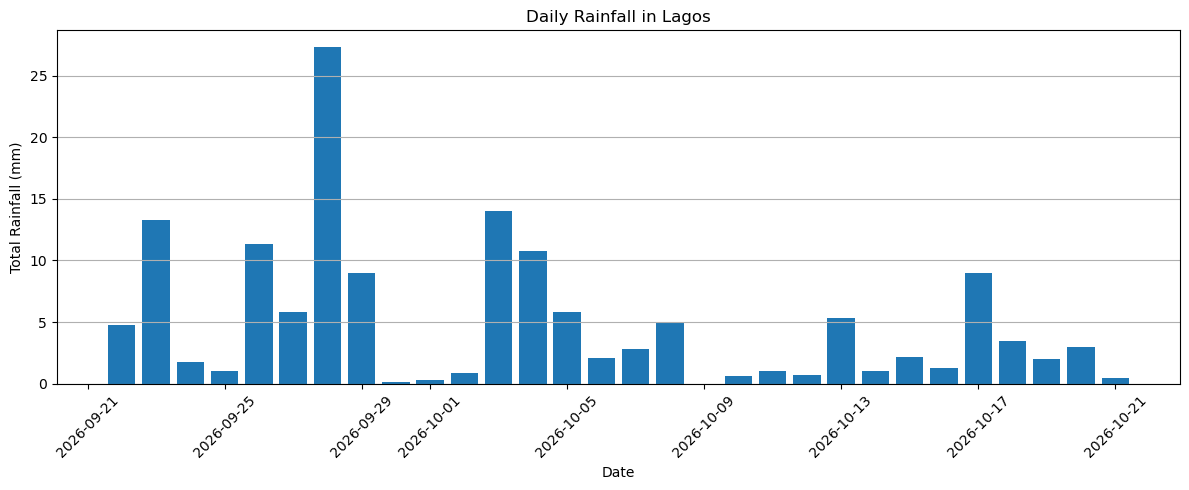

In [15]:
plt.figure(figsize=(12, 5))

plt.bar(daily_rainfall["time"], daily_rainfall["precipitation"])

plt.title("Daily Rainfall in Lagos")
plt.xlabel("Date")
plt.ylabel("Total Rainfall (mm)")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()

**Observation:** Daily rainfall varied throughout the study period, with September 28 recording the highest rainfall at approximately 27.3 mm. Rainfall generally decreased in October.

In [16]:
daily_humidity = (
    df.groupby(df["time"].dt.date)["relative_humidity_2m"]
    .mean()
    .reset_index()
)

daily_humidity.head()

,time,relative_humidity_2m
0,2026-09-22,84.708333
1,2026-09-23,88.375000
2,2026-09-24,83.708333
3,2026-09-25,84.625000
4,2026-09-26,85.750000


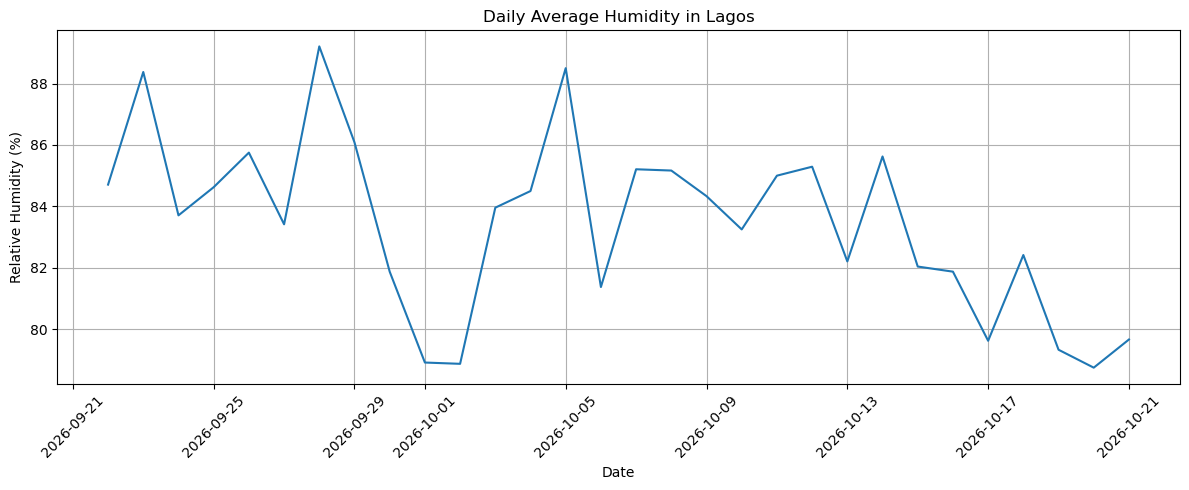

In [17]:
plt.figure(figsize=(12, 5))

plt.plot(daily_humidity["time"], daily_humidity["relative_humidity_2m"])

plt.title("Daily Average Humidity in Lagos")
plt.xlabel("Date")
plt.ylabel("Relative Humidity (%)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

**Observation:** Daily average humidity fluctuated throughout the study period, reaching approximately 89% in late September before declining to around 79% toward the end of October.

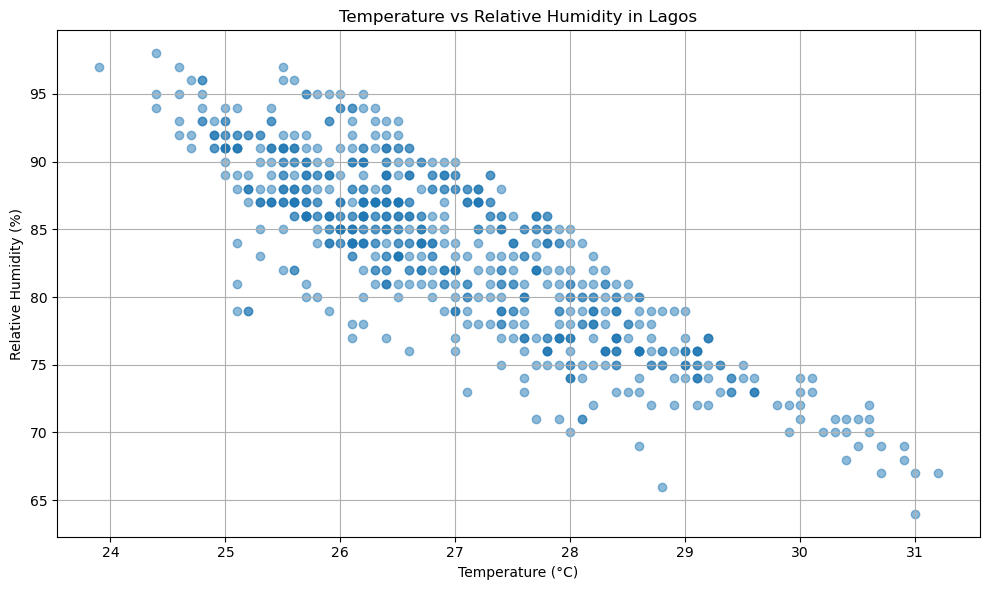

In [18]:
plt.figure(figsize=(10, 6))

plt.scatter(df["temperature_2m"], df["relative_humidity_2m"], alpha=0.5)

plt.title("Temperature vs Relative Humidity in Lagos")
plt.xlabel("Temperature (°C)")
plt.ylabel("Relative Humidity (%)")
plt.grid(True)
plt.tight_layout()
plt.show()

**Observation:** The scatter plot shows a strong negative relationship between temperature and relative humidity in Lagos. As temperature increases, relative humidity generally decreases.

In [19]:

corr =  df.corr(numeric_only=True)
corr

,temperature_2m,relative_humidity_2m,precipitation
temperature_2m,1.000000,-0.839773,-0.215420
relative_humidity_2m,-0.839773,1.000000,0.236563
precipitation,-0.215420,0.236563,1.000000


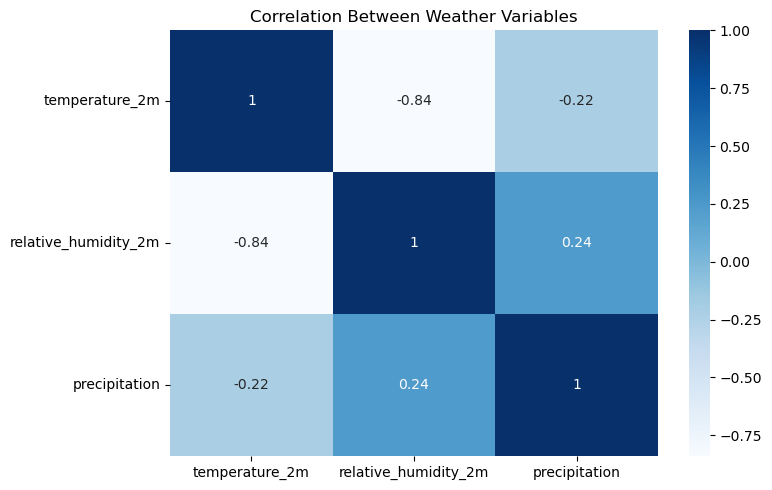

In [20]:
plt.figure(figsize=(8, 5))
sns.heatmap(corr, annot=True, cmap="Blues")
plt.title("Correlation Between Weather Variables")
plt.tight_layout()
plt.show()

**Observation:** Temperature and relative humidity show a strong negative correlation (-0.84), indicating that humidity decreases as temperature increases. Precipitation has a weak negative correlation with temperature (-0.20) and a weak positive correlation with relative humidity (0.23).

In [21]:
hottest_day = daily_temp.loc[daily_temp["temperature_2m"].idxmax()]

rainiest_day = daily_rainfall.loc[daily_rainfall["precipitation"].idxmax()]

print("Hottest day:")
print(hottest_day)

print("\nRainiest day:")
print(rainiest_day)

Hottest day:
time              2026-10-19
temperature_2m     28.733333
Name: 27, dtype: object

Rainiest day:
time             2026-09-28
precipitation          27.3
Name: 6, dtype: object


In [22]:
df.to_csv("lagos_weather_data.csv", index=False)

### Final Project Observations

**Observation:** The analysis of Lagos weather data revealed fluctuations in temperature, relative humidity, and precipitation throughout the study period. Temperature and relative humidity showed a strong negative correlation (-0.84), indicating that humidity generally decreased as temperature increased. Precipitation showed weak relationships with both variables. The hottest day was October 19, 2026, with an average temperature of 28.73°C, while the rainiest day was September 28, 2026, with 27.3 mm of rainfall.

**Conclusion:** The project provided insights into Lagos weather patterns, highlighting the relationship between temperature, humidity, and rainfall through exploratory data analysis and visualization.